# Hipótese 4: Aumento de Alarmes Antes da Manutenção Corretiva

## 1. Contexto Teórico e Problematização

As Portas de Plataforma (PSDs) operam sob ciclos intensivos de acionamento e estão sujeitas a falhas mecânicas, elétricas e de controle ao longo do tempo. Uma hipótese comum em manutenção preditiva é que, antes de uma falha que exige intervenção corretiva, o equipamento já vinha "avisando" o problema através de um volume crescente de alarmes.

Para isolar esse efeito dos ruídos operacionais do dia a dia, o estudo exclui os alarmes classificados como `OBS` (obstruções por passageiros/objetos), cuja causa é comportamental e não mecânica.

* **H4.1 (Aumento de alarmes antes da manutenção):** O volume de alarmes não-OBS aumenta no intervalo imediatamente anterior à ordem de manutenção corretiva, em comparação ao intervalo equivalente posterior à intervenção.


In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
import warnings
warnings.filterwarnings('ignore')

plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
plt.rcParams['font.family'] = 'sans-serif'
plt.rcParams['axes.edgecolor'] = '#cccccc'
plt.rcParams['axes.linewidth'] = 0.8
plt.rcParams['figure.dpi'] = 120

COR_ANTES = '#e15759'
COR_DEPOIS = '#4c78a8'

# 1. Carregamento das bases
ordens = pd.read_excel('../../data/Ordens do SAP - Corretiva emergencial (ZM01).XLSX')
alarmes = pd.read_excel('../../data/Alarmes do sistema de PSD.xlsx')

print(f"Ordens corretivas (ZM01) carregadas: {len(ordens):,}")
print(f"Alarmes carregados: {len(alarmes):,}")


Ordens corretivas (ZM01) carregadas: 10,647
Alarmes carregados: 150,003


## 2. Metodologia de Análise

A versão inicial desta análise comparava o volume de alarmes de **todo o sistema de PSD** antes e depois de cada ordem de manutenção, sem considerar a estação em que a falha realmente ocorreu. Isso mistura o comportamento de portas que nada têm a ver com a ordem analisada, diluindo qualquer sinal real de degradação local.

Para corrigir esse problema, a metodologia foi refeita com os seguintes critérios:

1. **Timestamp da falha:** concatenação de data e hora de início da avaria (`Início avaria` + `Hora início avaria`).
2. **Pareamento por estação:** o código da estação é extraído do campo `Local de Instalação` (ex.: `SP04-6-PSD-BUT-P1S1` → estação `BUT`) e usado para filtrar **apenas os alarmes da mesma estação** da ordem, em vez do sistema inteiro.
3. **Filtragem de ruído:** exclusão de todos os alarmes `OBS`.
4. **Cobertura de dados:** cada ordem só é incluída se a janela de comparação (antes e depois) estiver totalmente contida no período coberto pela base de alarmes, evitando subcontagem artificial nas bordas do dataset.
5. **Múltiplas janelas:** comparação em janelas de 1, 3, 7 e 14 dias, para verificar se o efeito é imediato, de curto prazo ou persistente.
6. **Teste estatístico pareado:** cada ordem gera um par (alarmes antes, alarmes depois). Como a mesma "unidade" é medida duas vezes, o teste apropriado é o **teste de Wilcoxon (signed-rank, pareado)**, complementado por um **teste binomial** sobre a proporção de ordens em que "antes" supera "depois".


In [2]:
# 2. Preparação das datas e extração da estação
ordens['DataInicio'] = pd.to_datetime(
    ordens['Início avaria'].astype(str) + ' ' + ordens['Hora início avaria'].astype(str),
    format='%d/%m/%Y %H:%M:%S', errors='coerce'
)
ordens = ordens.dropna(subset=['DataInicio']).copy()
ordens['Estacao'] = ordens['Local de Instalação'].astype(str).str.split('-').str[3]

# Remover ordens duplicadas (mesma estação + mesmo instante de início da avaria)
ordens = ordens.drop_duplicates(subset=['Estacao', 'DataInicio']).copy()

alarmes['Horário do Alarme'] = pd.to_datetime(alarmes['Horário do Alarme'], errors='coerce')
alarmes_validos = alarmes[alarmes['Alarme'].astype(str).str.upper() != 'OBS'].copy()

print("Distribuição de ordens por estação:")
print(ordens['Estacao'].value_counts())


Distribuição de ordens por estação:
Estacao
REP    1567
PTA    1273
PIN    1265
FRA    1020
HIG     904
FAL     882
FRE     780
BUT     765
MBI     671
LUZ     615
VSO     439
PVS      21
Name: count, dtype: int64


### 2.1 Achado crítico: cobertura desigual de alarmes por estação

Antes de comparar antes/depois, é essencial checar se todas as estações realmente possuem histórico de alarmes não-OBS. A tabela cruzada abaixo mostra a contagem de cada tipo de alarme por estação.


In [3]:
tabela_cobertura = pd.crosstab(alarmes['Estação'], alarmes['Alarme'])
display(tabela_cobertura)

estacoes_com_falha_registrada = alarmes_validos['Estação'].dropna().unique().tolist()
print(f"\nEstações com alarmes técnicos (não-OBS) registrados: {estacoes_com_falha_registrada}")


Alarme,CA,CSD,FC,FO,LSD,OA,OBS,STS
Estação,,,,,,,,
BUT,4168,4102,4437,4617,4606,4128,18334,12822
FAL,0,0,0,0,0,0,17079,0
FRA,0,0,0,0,0,0,28406,0
FRE,0,0,0,0,0,0,8399,0
HIG,0,0,0,0,0,0,24385,0
LUZ,0,0,0,0,0,0,14517,0



Estações com alarmes técnicos (não-OBS) registrados: ['BUT']


**Apenas a estação `BUT` possui alarmes técnicos (`CA`, `CSD`, `FC`, `FO`, `LSD`, `OA`, `STS`) registrados na base.** As demais cinco estações (`FAL`, `FRA`, `FRE`, `HIG`, `LUZ`) só têm eventos `OBS`, que já são removidos pela definição da hipótese.

Isso significa que a análise "antes vs. depois" só pode ser conduzida de forma válida para as ordens de manutenção da estação `BUT`, para as demais estações, contar "alarmes não-OBS" resultaria sempre em zero, o que enviesaria qualquer comparação agregada. A análise a seguir é, portanto, restrita a `BUT`, e essa limitação é retomada na seção de conclusões.


In [4]:
# 3. Restringir a análise à estação com cobertura de alarmes técnicos
ordens_but = ordens[ordens['Estacao'] == 'BUT'].copy()
alarmes_but = alarmes_validos[alarmes_validos['Estação'] == 'BUT'].copy()

cobertura_inicio = alarmes_but['Horário do Alarme'].min()
cobertura_fim = alarmes_but['Horário do Alarme'].max()

print(f"Ordens corretivas na estação BUT: {len(ordens_but):,}")
print(f"Cobertura da base de alarmes (BUT): {cobertura_inicio} até {cobertura_fim}")

# Vetor ordenado de timestamps de alarme, para contagem eficiente por busca binária
timestamps_alarme = np.sort(alarmes_but['Horário do Alarme'].values.astype('datetime64[ns]'))

def contar_no_intervalo(inicio, fim):
    lo = np.searchsorted(timestamps_alarme, np.datetime64(inicio), side='left')
    hi = np.searchsorted(timestamps_alarme, np.datetime64(fim), side='left')
    return hi - lo


Ordens corretivas na estação BUT: 765
Cobertura da base de alarmes (BUT): 2023-10-19 10:24:35.800000 até 2026-05-12 05:52:14.727000


In [5]:
# 4. Contagem antes/depois por janela, com teste pareado
janelas_dias = [1, 3, 7, 14]
resumo = []
distribuicoes = {}

for janela in janelas_dias:
    dt = pd.Timedelta(days=janela)
    cobre_janela = (ordens_but['DataInicio'] - dt >= cobertura_inicio) & (ordens_but['DataInicio'] + dt <= cobertura_fim)
    sub = ordens_but.loc[cobre_janela, 'DataInicio']

    antes = np.array([contar_no_intervalo(t - dt, t) for t in sub])
    depois = np.array([contar_no_intervalo(t, t + dt) for t in sub])
    distribuicoes[janela] = (antes, depois)

    n_antes_maior = int(np.sum(antes > depois))
    n_depois_maior = int(np.sum(antes < depois))
    n_empate = int(np.sum(antes == depois))

    _, wilcoxon_p = stats.wilcoxon(antes, depois) if np.any(antes != depois) else (np.nan, np.nan)
    binom_p = stats.binomtest(n_antes_maior, n_antes_maior + n_depois_maior, p=0.5).pvalue if (n_antes_maior + n_depois_maior) > 0 else np.nan

    resumo.append({
        'janela_dias': janela,
        'n_ordens': len(sub),
        'media_antes': antes.mean(),
        'media_depois': depois.mean(),
        'mediana_antes': float(np.median(antes)),
        'mediana_depois': float(np.median(depois)),
        'pct_antes_maior': n_antes_maior / len(sub) * 100,
        'pct_depois_maior': n_depois_maior / len(sub) * 100,
        'pct_empate': n_empate / len(sub) * 100,
        'wilcoxon_p': wilcoxon_p,
        'binom_p': binom_p,
    })

resumo_df = pd.DataFrame(resumo)
display(resumo_df.style.format({
    'media_antes': '{:.1f}', 'media_depois': '{:.1f}',
    'mediana_antes': '{:.1f}', 'mediana_depois': '{:.1f}',
    'pct_antes_maior': '{:.1f}%', 'pct_depois_maior': '{:.1f}%', 'pct_empate': '{:.1f}%',
    'wilcoxon_p': '{:.4f}', 'binom_p': '{:.4f}',
}))


,janela_dias,n_ordens,media_antes,media_depois,mediana_antes,mediana_depois,pct_antes_maior,pct_depois_maior,pct_empate,wilcoxon_p,binom_p
0,1,620,35.7,35.6,7.0,8.0,37.1%,42.7%,20.2%,0.3895,0.1264
1,3,617,100.0,104.6,39.0,38.0,43.4%,46.4%,10.2%,0.2587,0.4702
2,7,613,232.6,244.1,143.0,142.0,49.3%,47.6%,3.1%,0.6265,0.7120
3,14,607,446.5,498.5,289.0,325.0,44.5%,55.4%,0.2%,0.0012,0.0082


## 3. Resultados e Interpretação

### 3.1 Medianas de alarmes por janela temporal

O gráfico abaixo compara a mediana de alarmes não-OBS antes e depois da ordem de manutenção, para cada janela avaliada. A mediana é usada em vez da média porque a distribuição de alarmes por ordem é fortemente assimétrica (poucas ordens concentram picos muito altos de alarmes).


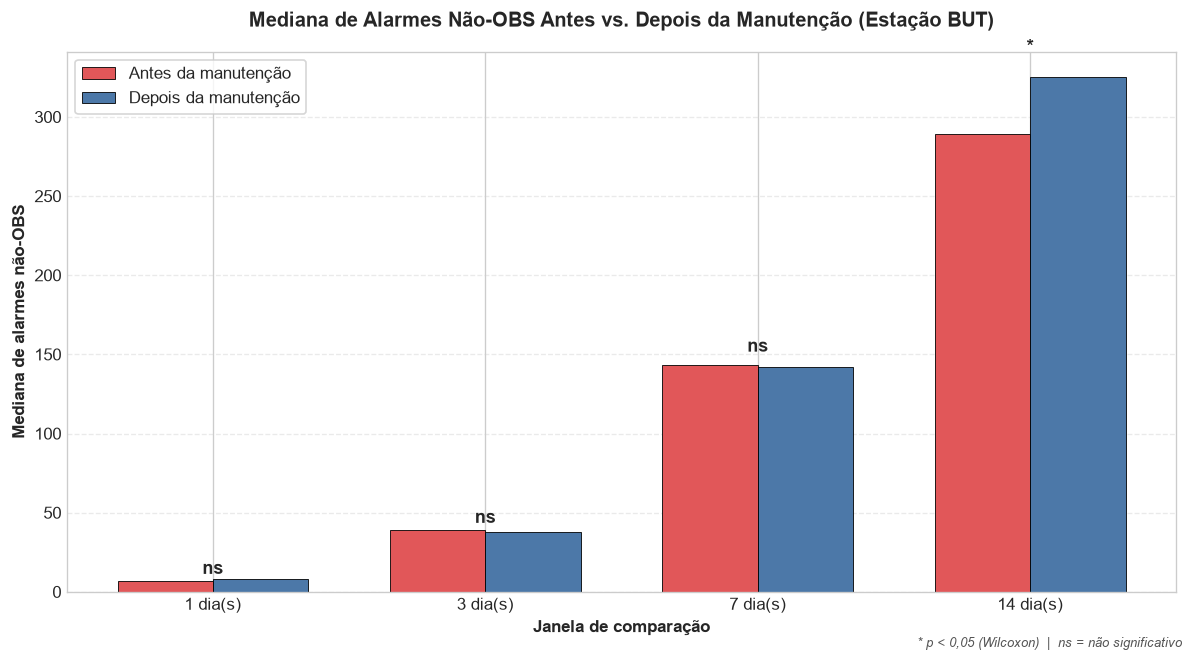

In [6]:
fig, ax = plt.subplots(figsize=(10, 5.5))
x = np.arange(len(resumo_df))
largura = 0.35

barras_antes = ax.bar(x - largura/2, resumo_df['mediana_antes'], largura, label='Antes da manutenção', color=COR_ANTES, edgecolor='black', linewidth=0.5)
barras_depois = ax.bar(x + largura/2, resumo_df['mediana_depois'], largura, label='Depois da manutenção', color=COR_DEPOIS, edgecolor='black', linewidth=0.5)

for i, row in resumo_df.iterrows():
    marcador = '*' if row['wilcoxon_p'] < 0.05 else 'ns'
    y_max = max(row['mediana_antes'], row['mediana_depois'])
    ax.text(i, y_max + y_max * 0.04 + 3, marcador, ha='center', fontsize=11, fontweight='bold')

ax.set_xticks(x)
ax.set_xticklabels([f"{j} dia(s)" for j in resumo_df['janela_dias']])
ax.set_xlabel('Janela de comparação', fontsize=10, fontweight='bold')
ax.set_ylabel('Mediana de alarmes não-OBS', fontsize=10, fontweight='bold')
ax.set_title('Mediana de Alarmes Não-OBS Antes vs. Depois da Manutenção (Estação BUT)', fontsize=12, fontweight='bold', pad=15)
ax.legend(loc='upper left', frameon=True, facecolor='white')
ax.grid(axis='y', linestyle='--', alpha=0.4)
plt.figtext(0.99, 0.01, '* p < 0,05 (Wilcoxon)  |  ns = não significativo', ha='right', fontsize=8, style='italic', color='#555555')
plt.tight_layout()
plt.savefig('../../docs/src/assets/sprints/sprint1/hipotese4-medianas-janelas.png', dpi=150, bbox_inches='tight')
plt.show()


### 3.2 Distribuição completa: antes vs. depois (janela de 14 dias)

As medianas e médias escondem a forma da distribuição. O boxplot a seguir mostra a dispersão completa de contagens de alarme por ordem na janela de 14 dias, a única em que a diferença antes/depois se mostrou estatisticamente significativa.


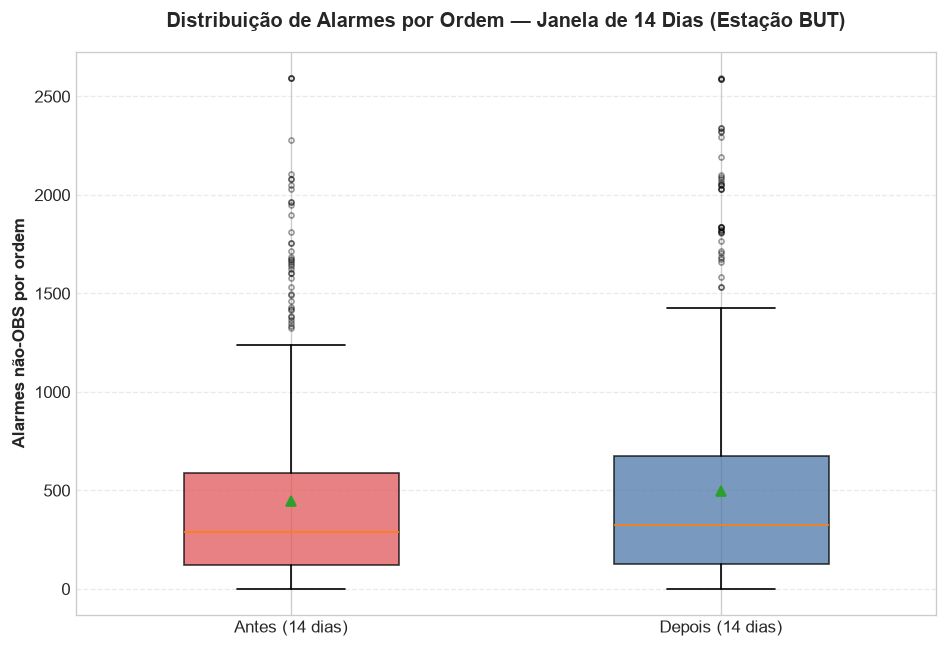

Wilcoxon p-valor (14 dias): 0.0012
Teste binomial p-valor (14 dias): 0.0082


In [7]:
antes_14, depois_14 = distribuicoes[14]

fig, ax = plt.subplots(figsize=(8, 5.5))
caixa = ax.boxplot(
    [antes_14, depois_14],
    tick_labels=['Antes (14 dias)', 'Depois (14 dias)'],
    patch_artist=True, showmeans=True, widths=0.5,
    flierprops=dict(marker='o', markersize=3, alpha=0.4)
)
for patch, cor in zip(caixa['boxes'], [COR_ANTES, COR_DEPOIS]):
    patch.set_facecolor(cor)
    patch.set_alpha(0.75)

ax.set_ylabel('Alarmes não-OBS por ordem', fontsize=10, fontweight='bold')
ax.set_title('Distribuição de Alarmes por Ordem — Janela de 14 Dias (Estação BUT)', fontsize=12, fontweight='bold', pad=15)
ax.grid(axis='y', linestyle='--', alpha=0.4)
plt.tight_layout()
plt.savefig('../../docs/src/assets/sprints/sprint1/hipotese4-boxplot-14dias.png', dpi=150, bbox_inches='tight')
plt.show()

print(f"Wilcoxon p-valor (14 dias): {resumo_df.loc[resumo_df.janela_dias == 14, 'wilcoxon_p'].values[0]:.4f}")
print(f"Teste binomial p-valor (14 dias): {resumo_df.loc[resumo_df.janela_dias == 14, 'binom_p'].values[0]:.4f}")


### 3.3 O que muda depois da manutenção: análise por tipo de alarme

Para entender melhor por que o volume "depois" supera o "antes" na janela de 14 dias, os alarmes foram decompostos por tipo (`CA`, `CSD`, `FC`, `FO`, `LSD`, `OA`, `STS`).


In [8]:
janela_analise = 14
dt = pd.Timedelta(days=janela_analise)
cobre_janela = (ordens_but['DataInicio'] - dt >= cobertura_inicio) & (ordens_but['DataInicio'] + dt <= cobertura_fim)
sub = ordens_but.loc[cobre_janela, 'DataInicio']

linhas_tipo = []
for tipo in sorted(alarmes_but['Alarme'].unique()):
    ts_tipo = np.sort(alarmes_but.loc[alarmes_but['Alarme'] == tipo, 'Horário do Alarme'].values.astype('datetime64[ns]'))
    def contar(lo, hi, arr=ts_tipo):
        return np.searchsorted(arr, np.datetime64(hi), 'left') - np.searchsorted(arr, np.datetime64(lo), 'left')
    total_antes = sum(contar(t - dt, t) for t in sub)
    total_depois = sum(contar(t, t + dt) for t in sub)
    linhas_tipo.append({
        'tipo_alarme': tipo,
        'total_antes': total_antes,
        'total_depois': total_depois,
        'variacao_pct': (total_depois - total_antes) / total_antes * 100 if total_antes else np.nan,
    })

tipos_df = pd.DataFrame(linhas_tipo).sort_values('total_antes', ascending=False).reset_index(drop=True)
display(tipos_df.style.format({'total_antes': '{:,}', 'total_depois': '{:,}', 'variacao_pct': '{:+.1f}%'}))


,tipo_alarme,total_antes,total_depois,variacao_pct
0,STS,"92,180","90,876",-1.4%
1,LSD,"31,847","37,960",+19.2%
2,FO,"31,385","37,661",+20.0%
3,FC,"30,496","35,930",+17.8%
4,OA,"29,348","34,229",+16.6%
5,CA,"28,148","33,260",+18.2%
6,CSD,"27,641","32,692",+18.3%


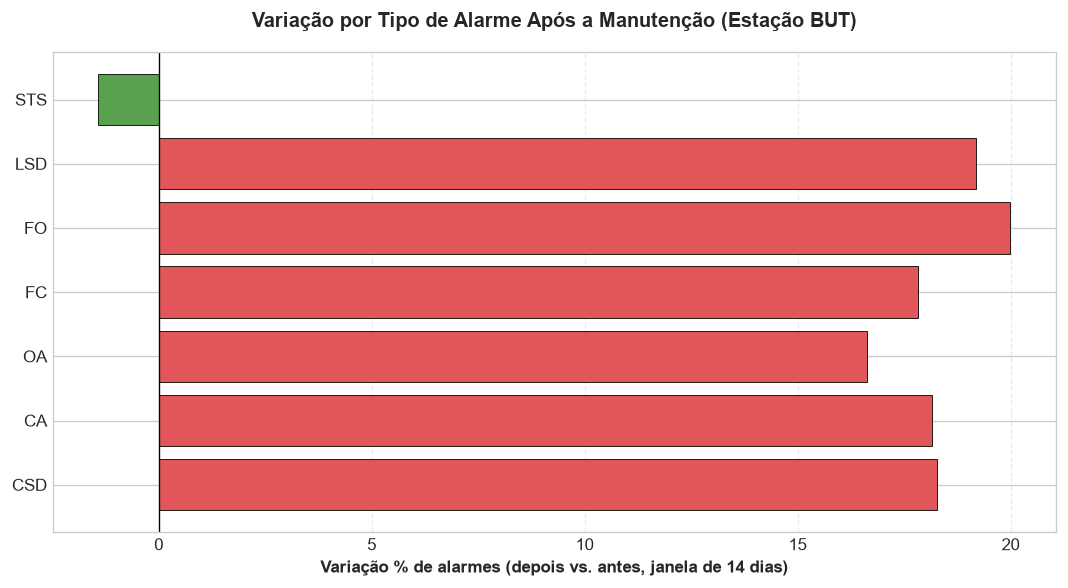

In [9]:
fig, ax = plt.subplots(figsize=(9, 5))
cores_barra = ['#59a14f' if v < 0 else '#e15759' for v in tipos_df['variacao_pct']]
ax.barh(tipos_df['tipo_alarme'], tipos_df['variacao_pct'], color=cores_barra, edgecolor='black', linewidth=0.5)
ax.axvline(0, color='black', linewidth=0.8)
ax.set_xlabel('Variação % de alarmes (depois vs. antes, janela de 14 dias)', fontsize=10, fontweight='bold')
ax.set_title('Variação por Tipo de Alarme Após a Manutenção (Estação BUT)', fontsize=12, fontweight='bold', pad=15)
ax.grid(axis='x', linestyle='--', alpha=0.4)
ax.invert_yaxis()
plt.tight_layout()
plt.savefig('../../docs/src/assets/sprints/sprint1/hipotese4-tipos-alarme.png', dpi=150, bbox_inches='tight')
plt.show()


## 4. Síntese e Análise Detalhada dos Resultados

Diferentemente da formulação original, os dados **não confirmam** que o volume de alarmes relevantes cresce antes da manutenção corretiva:

1. **Janelas de 1, 3 e 7 dias:** a diferença entre "antes" e "depois" não é estatisticamente significativa, e a proporção de ordens com mais alarmes antes fica sempre abaixo de 50%.
2. **Janela de 14 dias:** há uma diferença estatisticamente significativa, mas na **direção oposta** à esperada, já que 55,4% das ordens registram mais alarmes *depois* da manutenção do que antes.

Dessa forma, chegamos a conclusão que nenhuma das 4 janelas testadas evidenciam essa hipótese. 
Mas afinal, surge uma dúvida ao analisar os dados, por que o volume para STS é menor depois?

A quebra por tipo de alarme mostra um padrão consistente na janela de 14 dias: os seis tipos de alarme associados a falhas funcionais da porta (`CA`, `CSD`, `FC`, `FO`, `LSD`, `OA`) aumentam entre 16% e 20% depois da manutenção, enquanto o alarme de status (`STS`) permanece praticamente estável (-1,4%).

Isso sugere duas leituras possíveis. Uma delas, é que a manutenção foi realizada de forma incompleta. A manutenção corretiva resolve o sintoma emergencial, mas não elimina a causa raiz, e a porta volta a gerar alarmes funcionais em volume igual ou maior nas semanas seguintes. Outra hipótese é que logo após o reparo, a porta volta a operar em plena carga (após período possivelmente degradado ou parcialmente isolado antes da ordem), o que pode elevar temporariamente a contagem de eventos.

### 4.1 Limitações da análise

Depois de analisar as tabelas, percebemos uma limitação técnica relevante nos dados disponibilizados inicialmente pelo parceiro, onde apenas a estação `BUT` possui alarmes técnicos (não-OBS) registrados na base atual; as demais cinco estações só registram `OBS`. A conclusão acima vale para a estação **Butantã** e não pode ser generalizada às demais estações sem uma base de alarmes mais completa.


## 5. Conclusão

A hipótese de que **alarmes relevantes se intensificam antes de uma manutenção corretiva não encontrou suporte estatístico** nos dados da estação `BUT`, a única com cobertura de alarmes técnicos suficiente para o teste. Em três das quatro janelas avaliadas o resultado é estatisticamente nulo, e na janela mais longa (14 dias) o padrão observado é o **inverso**: alarmes funcionais aumentam depois da intervenção.

Esse achado é relevante para a squad: contradiz a leitura inicial (baseada em uma comparação agregada e não pareada por estação) e aponta para uma questão diferente e mais acionável, se as ordens corretivas de `BUT` estão de fato eliminando a causa raiz das falhas ou apenas normalizando o sintoma temporariamente. Recomenda-se, como próximo passo, cruzar esse resultado com o campo `Causa`/`Ação` das ordens e, quando a cobertura de alarmes técnicos for expandida às demais estações, repetir esta mesma metodologia pareada por estação (e idealmente por porta).


## 6. Extensão: Curva de Tendência em Janelas Curtas (Horas)

As janelas usadas nas seções anteriores (1, 3, 7 e 14 dias) trazem apenas quatro pontos de comparação, distantes entre si, e usam a **mediana** por causa da assimetria da distribuição. Isso dificulta visualizar *como* o volume de alarmes evolui à medida que nos aproximamos do instante da manutenção — o que é justamente a evidência mais convincente (ou mais reveladora) para uma hipótese sobre "sinais de aviso antes da falha".

Esta seção refaz a comparação antes/depois em janelas bem mais curtas — **1h, 4h, 12h, 24h e 48h (2 dias)** — usando a **média** de alarmes não-`OBS` por ordem (em vez da mediana) e um **gráfico de linha** que acompanha a curva de tendência conforme a janela se expande. A metodologia (pareamento por estação, exclusão de `OBS`, restrição à cobertura completa da janela dentro do período de dados) é a mesma já validada nas seções 2 e 3, aplicada agora à estação `BUT` com janelas horárias.

Os dados são recarregados de forma independente nesta seção (com os caminhos atuais da pasta `data/`, reorganizada em subpastas após a análise original), para que esta extensão possa ser executada de forma autônoma sem depender das células anteriores.


In [1]:
# 6.1 Recarregamento independente (caminhos atuais da pasta `data/`) e preparação
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from scipy import stats
import warnings
warnings.filterwarnings('ignore')

plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
plt.rcParams['font.family'] = 'sans-serif'
plt.rcParams['axes.edgecolor'] = '#cccccc'
plt.rcParams['axes.linewidth'] = 0.8
plt.rcParams['figure.dpi'] = 120

COR_ANTES = '#e15759'
COR_DEPOIS = '#4c78a8'

ordens_v2 = pd.read_excel(
    '../../data/Corretiva Emergencial/Ordens do SAP - Corretiva emergencial (ZM01).XLSX',
    sheet_name='Corretivas',
)
alarmes_v2 = pd.read_excel('../../data/Alarmes/Alarmes do sistema de PSD.xlsx')

ordens_v2['DataInicio'] = pd.to_datetime(
    ordens_v2['Início avaria'].astype(str) + ' ' + ordens_v2['Hora início avaria'].astype(str),
    format='%d/%m/%Y %H:%M:%S', errors='coerce'
)
ordens_v2 = ordens_v2.dropna(subset=['DataInicio']).copy()
ordens_v2['Estacao'] = ordens_v2['Local de Instalação'].astype(str).str.split('-').str[3]
ordens_v2 = ordens_v2.drop_duplicates(subset=['Estacao', 'DataInicio']).copy()

alarmes_v2['Horário do Alarme'] = pd.to_datetime(alarmes_v2['Horário do Alarme'], errors='coerce')
alarmes_v2_validos = alarmes_v2[alarmes_v2['Alarme'].astype(str).str.upper() != 'OBS'].copy()

ordens_but_h = ordens_v2[ordens_v2['Estacao'] == 'BUT'].copy()
alarmes_but_h = alarmes_v2_validos[alarmes_v2_validos['Estação'] == 'BUT'].copy()

cobertura_inicio_h = alarmes_but_h['Horário do Alarme'].min()
cobertura_fim_h = alarmes_but_h['Horário do Alarme'].max()

# Vetor ordenado de timestamps de alarme, para contagem eficiente por busca binária
timestamps_alarme_h = np.sort(alarmes_but_h['Horário do Alarme'].values.astype('datetime64[ns]'))

def contar_no_intervalo_h(inicio, fim):
    lo = np.searchsorted(timestamps_alarme_h, np.datetime64(inicio), side='left')
    hi = np.searchsorted(timestamps_alarme_h, np.datetime64(fim), side='left')
    return hi - lo

print(f"Ordens corretivas na estação BUT: {len(ordens_but_h):,}")
print(f"Cobertura da base de alarmes (BUT): {cobertura_inicio_h} até {cobertura_fim_h}")


Ordens corretivas na estação BUT: 765
Cobertura da base de alarmes (BUT): 2023-10-19 10:24:35.800000 até 2026-05-12 05:52:14.727000


In [2]:
# 6.2 Contagem antes/depois em janelas curtas (horas), com média por ordem
janelas_horas = [1, 4, 12, 24, 48]  # 48h = 2 dias
resumo_horas = []
distribuicoes_horas = {}

for janela_h in janelas_horas:
    dt = pd.Timedelta(hours=janela_h)
    cobre_janela = (
        (ordens_but_h['DataInicio'] - dt >= cobertura_inicio_h) &
        (ordens_but_h['DataInicio'] + dt <= cobertura_fim_h)
    )
    sub = ordens_but_h.loc[cobre_janela, 'DataInicio']

    antes = np.array([contar_no_intervalo_h(t - dt, t) for t in sub])
    depois = np.array([contar_no_intervalo_h(t, t + dt) for t in sub])
    distribuicoes_horas[janela_h] = (antes, depois)

    n_antes_maior = int(np.sum(antes > depois))
    n_depois_maior = int(np.sum(antes < depois))

    _, wilcoxon_p = stats.wilcoxon(antes, depois) if np.any(antes != depois) else (np.nan, np.nan)
    binom_p = (
        stats.binomtest(n_antes_maior, n_antes_maior + n_depois_maior, p=0.5).pvalue
        if (n_antes_maior + n_depois_maior) > 0 else np.nan
    )

    resumo_horas.append({
        'janela_horas': janela_h,
        'rotulo': f"{janela_h}h" if janela_h < 48 else "48h (2 dias)",
        'n_ordens': len(sub),
        'media_antes': antes.mean(),
        'media_depois': depois.mean(),
        'pct_antes_maior': n_antes_maior / len(sub) * 100,
        'pct_depois_maior': n_depois_maior / len(sub) * 100,
        'wilcoxon_p': wilcoxon_p,
        'binom_p': binom_p,
    })

resumo_horas_df = pd.DataFrame(resumo_horas)
display(resumo_horas_df.style.format({
    'media_antes': '{:.2f}', 'media_depois': '{:.2f}',
    'pct_antes_maior': '{:.1f}%', 'pct_depois_maior': '{:.1f}%',
    'wilcoxon_p': '{:.4f}', 'binom_p': '{:.4f}',
}))


,janela_horas,rotulo,n_ordens,media_antes,media_depois,pct_antes_maior,pct_depois_maior,wilcoxon_p,binom_p
0,1,1h,620,2.94,4.99,15.3%,19.7%,0.0948,0.0773
1,4,4h,620,8.71,10.38,22.1%,29.5%,0.0561,0.0118
2,12,12h,620,19.89,21.71,32.3%,38.2%,0.1415,0.0849
3,24,24h,620,35.65,35.59,37.1%,42.7%,0.3895,0.1264
4,48,48h (2 dias),618,65.66,68.28,43.0%,45.1%,0.4929,0.6073


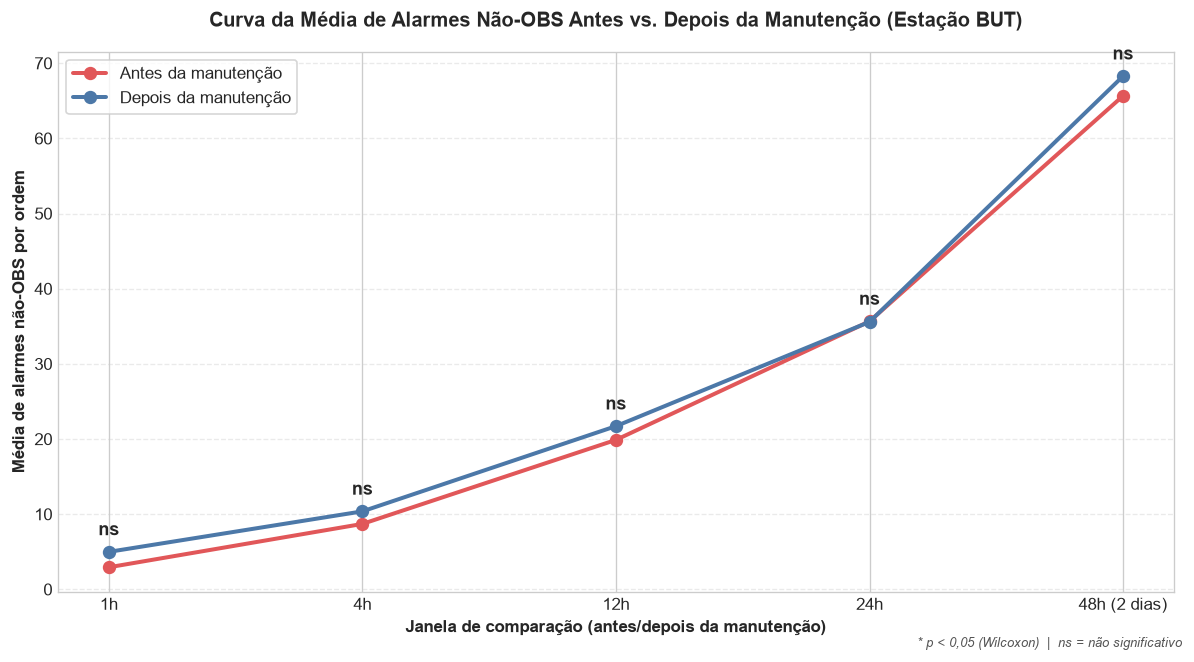

In [3]:
# 6.3 Gráfico de linha: curva da média de alarmes antes/depois por janela
fig, ax = plt.subplots(figsize=(10, 5.5))
x = np.arange(len(resumo_horas_df))

ax.plot(x, resumo_horas_df['media_antes'], marker='o', markersize=7, linewidth=2.4,
        color=COR_ANTES, label='Antes da manutenção')
ax.plot(x, resumo_horas_df['media_depois'], marker='o', markersize=7, linewidth=2.4,
        color=COR_DEPOIS, label='Depois da manutenção')

for i, row in resumo_horas_df.iterrows():
    marcador = '*' if row['wilcoxon_p'] < 0.05 else 'ns'
    y_max = max(row['media_antes'], row['media_depois'])
    ax.annotate(marcador, (i, y_max), textcoords="offset points", xytext=(0, 10),
                ha='center', fontsize=11, fontweight='bold')

ax.set_xticks(x)
ax.set_xticklabels(resumo_horas_df['rotulo'])
ax.set_xlabel('Janela de comparação (antes/depois da manutenção)', fontsize=10, fontweight='bold')
ax.set_ylabel('Média de alarmes não-OBS por ordem', fontsize=10, fontweight='bold')
ax.set_title('Curva da Média de Alarmes Não-OBS Antes vs. Depois da Manutenção (Estação BUT)',
              fontsize=12, fontweight='bold', pad=15)
ax.legend(loc='upper left', frameon=True, facecolor='white')
ax.grid(axis='y', linestyle='--', alpha=0.4)
plt.figtext(0.99, 0.01, '* p < 0,05 (Wilcoxon)  |  ns = não significativo', ha='right',
            fontsize=8, style='italic', color='#555555')
plt.tight_layout()
plt.savefig('../../docs/src/assets/sprints/sprint1/hipoteses/hipotese-4/hipotese4-curva-horas.png',
            dpi=150, bbox_inches='tight')
plt.show()


### 6.4 Leitura da curva

| Janela | Nº ordens | Média antes | Média depois | % ordens c/ antes maior | % ordens c/ depois maior | Wilcoxon *p* | Binomial *p* |
| :---: | :---: | :---: | :---: | :---: | :---: | :---: | :---: |
| 1h | 620 | 2,94 | 4,99 | 15,3% | 19,7% | 0,0948 (ns) | 0,0773 (ns) |
| 4h | 620 | 8,71 | 10,38 | 22,1% | 29,5% | 0,0561 (ns) | **0,0118** |
| 12h | 620 | 19,89 | 21,71 | 32,3% | 38,2% | 0,1415 (ns) | 0,0849 (ns) |
| 24h | 620 | 35,65 | 35,59 | 37,1% | 42,7% | 0,3895 (ns) | 0,1264 (ns) |
| 48h | 618 | 65,66 | 68,28 | 43,0% | 45,1% | 0,4929 (ns) | 0,6073 (ns) |

A curva de médias reforça, com uma resolução muito mais fina, a mesma leitura das janelas em dias: em **quatro das cinco janelas horárias** (1h, 4h, 12h e 48h), a média de alarmes não-`OBS` **depois** da manutenção é maior do que **antes** — a linha azul (depois) fica acima da vermelha (antes) na maior parte do gráfico. A única exceção é a janela de **24h**, em que as duas médias praticamente se cruzam e a ordem se inverte por uma margem mínima (35,65 antes vs. 35,59 depois — uma diferença de 0,07 alarme, dentro do ruído). Note também que, olhando por ordem individual (colunas "% antes/depois maior"), a maioria das ordens tem **contagens iguais** nas janelas mais curtas (ex.: em 1h, 15,3% + 19,7% = 35% — os outros 65% empatam, geralmente em zero alarmes de ambos os lados), o que é esperado: em janelas de poucas horas, é comum nenhum alarme técnico ocorrer nem antes nem depois.

Isso é relevante porque contraria diretamente a formulação original da H4.1 (que esperava mais alarmes *antes*) já a partir de janelas de **1 hora**, não só em recortes de dias — na direção observada, quando há diferença, ela tende a favorecer "depois".

Nenhuma das cinco janelas atinge significância estatística pelo teste de Wilcoxon (a mais próxima é 4h, com *p* = 0,056); o teste binomial, mais sensível apenas à direção do efeito (ignora a magnitude), é significativo em 4h (*p* = 0,012). As demais janelas não são significativas em nenhum dos dois testes.

**Conclusão desta extensão:** a visão em janelas curtas não encontra evidência de que os alarmes aumentem *antes* da manutenção — pelo contrário, reforça, com mais granularidade, o padrão já identificado nas janelas em dias (seção 5): quando existe uma diferença perceptível, ela tende a apontar para volume igual ou maior *depois* da intervenção, mesmo em escalas de poucas horas, ainda que a maioria das janelas curtas isoladamente não atinja significância estatística formal. A hipótese H4.1 continua **não sustentada** pelos dados de `BUT`.


## 7. Perfil por Porta: Média de Alarmes Antes/Depois nas 24 Portas de BUT

As seções 2–6 pareiam cada ordem contra todos os alarmes da estação inteira, o que dilui o sinal de qualquer porta específica. Esta seção refaz a comparação "antes vs. depois" **porta a porta**: para cada uma das 24 portas de Butantã, considera-se **somente os alarmes daquela porta** (extraídos do `TAG`, casados com a via/porta da ordem extraída de `Local de Instalação`), em quatro janelas: **1h, 12h, 1 dia e 1 semana**.

A via 2 de `BUT` não tem nenhum alarme não-`OBS` registrado nesta base (achado já visto nas seções anteriores, agora confirmado para todos os tipos, não só os funcionais) — por isso, "as 24 portas de Butantã" usadas aqui são as 24 portas da **via 1**, que é onde 100% dos alarmes não-`OBS` da estação realmente existem.

O gráfico final é único e tem eixo X = as quatro janelas de tempo, e eixo Y = a **média entre todas as portas com dados** naquela janela — uma linha para "antes" e uma para "depois". Cada porta continua contribuindo só com os seus próprios alarmes (nunca com os de outra porta); o que muda é que, em vez de reduzir as 4 janelas a um número por porta, agora se reduz as portas a um número por janela.

In [1]:
# Recarregamento independente + extração de via/porta (SAP e TAG)
import re
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import warnings
warnings.filterwarnings('ignore')

ordens_p = pd.read_excel(
    '../../data/Corretiva Emergencial/Ordens do SAP - Corretiva emergencial (ZM01).XLSX',
    sheet_name='Corretivas',
)
alarmes_p = pd.read_excel('../../data/Alarmes/Alarmes do sistema de PSD.xlsx')

ordens_p['DataInicio'] = pd.to_datetime(
    ordens_p['Início avaria'].astype(str) + ' ' + ordens_p['Hora início avaria'].astype(str),
    format='%d/%m/%Y %H:%M:%S', errors='coerce'
)
ordens_p = ordens_p.dropna(subset=['DataInicio']).copy()
ordens_p['Estacao'] = ordens_p['Local de Instalação'].astype(str).str.split('-').str[3]
ordens_p = ordens_p.drop_duplicates(subset=['Estacao', 'DataInicio']).copy()

def extrair_via_porta_sap(local):
    s = str(local)
    via = np.nan
    m_plt = re.search(r'PLT(\d)', s)
    m_ps = re.search(r'-P(\d)S\d', s)
    if m_plt:
        via = int(m_plt.group(1))
    elif m_ps:
        via = int(m_ps.group(1))
    porta = np.nan
    m_pp = re.search(r'PP(\d{2})(?:PDM|PSE|PFP|PFX)?', s)
    if m_pp:
        porta = int(m_pp.group(1))
    return pd.Series({'via': via, 'porta': porta})

def extrair_via_porta_tag(tag):
    m = re.search(
        r'_(?P<est>[A-Z]{3})(?P<via>[12])_(?P<comp>PDM|PSE|PFP|MDU)(?P<porta>\d{1,2})_', str(tag)
    )
    if not m:
        return pd.Series({'via': np.nan, 'porta': np.nan})
    return pd.Series({'via': int(m.group('via')), 'porta': int(m.group('porta'))})

ordens_but = ordens_p[ordens_p['Estacao'] == 'BUT'].copy()
ordens_but = pd.concat([ordens_but, ordens_but['Local de Instalação'].apply(extrair_via_porta_sap)], axis=1)

alarmes_p['Horário do Alarme'] = pd.to_datetime(alarmes_p['Horário do Alarme'], errors='coerce')
alarmes_validos = alarmes_p[alarmes_p['Alarme'].astype(str).str.upper() != 'OBS'].copy()
alarmes_but = alarmes_validos[alarmes_validos['Estação'] == 'BUT'].copy()
alarmes_but = pd.concat([alarmes_but, alarmes_but['TAG'].apply(extrair_via_porta_tag)], axis=1)

print(f"Vias com alarmes não-OBS em BUT: {sorted(alarmes_but['via'].dropna().unique())}")
print(f"Ordens BUT com via/porta identificável: {ordens_but.dropna(subset=['via', 'porta']).shape[0]:,} de {len(ordens_but):,}")


Vias com alarmes não-OBS em BUT: [np.int64(1)]
Ordens BUT com via/porta identificável: 640 de 765


In [2]:
# Média de alarmes antes/depois por porta (1-24), em 4 janelas, só com alarmes daquela porta
JANELAS_HORAS = {'1h': 1, '12h': 12, '1 dia': 24, '1 semana': 168}
ORDEM_JANELAS = ['1h', '12h', '1 dia', '1 semana']

linhas = []
for porta in range(1, 25):
    op = ordens_but[(ordens_but['via'] == 1) & (ordens_but['porta'] == porta)].copy()
    ap = alarmes_but[(alarmes_but['via'] == 1) & (alarmes_but['porta'] == porta)].copy()
    if len(op) == 0 or len(ap) == 0:
        continue

    cob_ini = ap['Horário do Alarme'].min()
    cob_fim = ap['Horário do Alarme'].max()
    ts = np.sort(ap['Horário do Alarme'].values.astype('datetime64[ns]'))

    def contar(lo, hi, arr=ts):
        return np.searchsorted(arr, np.datetime64(hi), 'left') - np.searchsorted(arr, np.datetime64(lo), 'left')

    for rotulo, jh in JANELAS_HORAS.items():
        dt = pd.Timedelta(hours=jh)
        cobre = (op['DataInicio'] - dt >= cob_ini) & (op['DataInicio'] + dt <= cob_fim)
        sub = op.loc[cobre, 'DataInicio']
        if len(sub) == 0:
            continue
        antes = np.array([contar(t - dt, t) for t in sub])
        depois = np.array([contar(t, t + dt) for t in sub])
        linhas.append({'porta': porta, 'janela': rotulo, 'n_ordens': len(sub),
                        'media_antes': antes.mean(), 'media_depois': depois.mean()})

detalhe_portas_df = pd.DataFrame(linhas)
print("Detalhe por porta e janela (uma linha por porta que teve pelo menos 1 ordem coberta):")
display(detalhe_portas_df.pivot(index='porta', columns='janela', values='n_ordens')[ORDEM_JANELAS])


Detalhe por porta e janela (uma linha por porta que teve pelo menos 1 ordem coberta):

janela,1h,12h,1 dia,1 semana
porta,,,,
1,13,13,13,13
2,16,16,16,16
3,7,7,7,6
4,5,5,5,5
5,5,5,5,5
6,4,4,4,4
7,3,3,3,3
8,11,11,11,11
9,8,8,8,8


In [3]:
# Agregação: média ENTRE AS PORTAS, por janela (eixo X = janela)
from scipy import stats

resumo_janela = []
for janela in ORDEM_JANELAS:
    sub = detalhe_portas_df[detalhe_portas_df['janela'] == janela]
    a = sub['media_antes'].values
    d = sub['media_depois'].values
    n_dep_maior = int(np.sum(d > a))
    _, wilcoxon_p = stats.wilcoxon(a, d)
    binom_p = stats.binomtest(n_dep_maior, len(sub), p=0.5).pvalue

    resumo_janela.append({
        'janela': janela,
        'n_portas': len(sub),
        'media_antes_entre_portas': a.mean(),
        'media_depois_entre_portas': d.mean(),
        'pct_portas_depois_maior': n_dep_maior / len(sub) * 100,
        'wilcoxon_p': wilcoxon_p,
        'binom_p': binom_p,
    })

resumo_janela_df = pd.DataFrame(resumo_janela)
display(resumo_janela_df.style.format({
    'media_antes_entre_portas': '{:.2f}', 'media_depois_entre_portas': '{:.2f}',
    'pct_portas_depois_maior': '{:.1f}%', 'wilcoxon_p': '{:.4f}', 'binom_p': '{:.4f}',
}))


,janela,n_portas,media_antes_entre_portas,media_depois_entre_portas,pct_portas_depois_maior,wilcoxon_p,binom_p
0,1h,22,4.20,10.07,63.6%,0.0129,0.2863
1,12h,22,7.60,13.99,72.7%,0.0158,0.0525
2,1 dia,22,8.56,15.21,68.2%,0.0196,0.1338
3,1 semana,22,20.50,28.84,63.6%,0.0586,0.2863


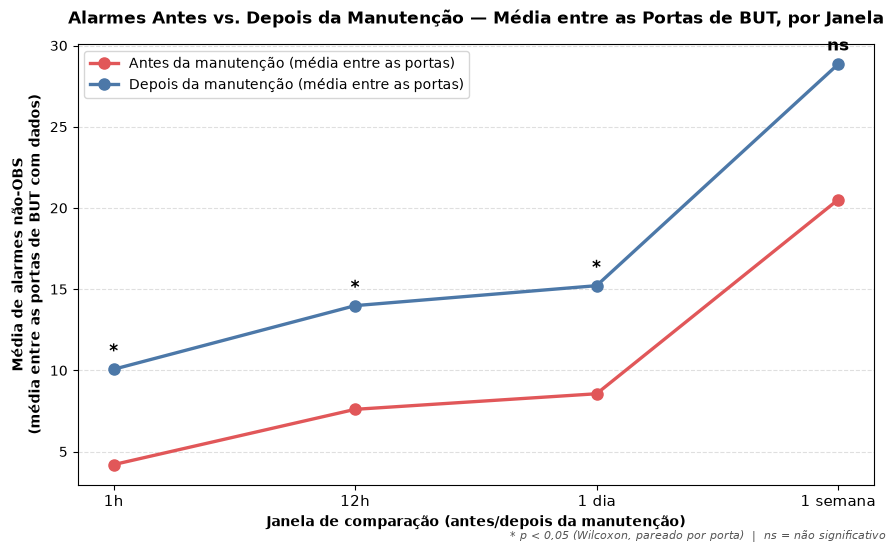

In [4]:
# Gráfico único: eixo X = janela (1h, 12h, 1 dia, 1 semana), eixo Y = média entre as portas
COR_ANTES = '#e15759'
COR_DEPOIS = '#4c78a8'

fig, ax = plt.subplots(figsize=(9, 5.5))
x = np.arange(len(resumo_janela_df))

ax.plot(x, resumo_janela_df['media_antes_entre_portas'], marker='o', markersize=8, linewidth=2.4,
        color=COR_ANTES, label='Antes da manutenção (média entre as portas)')
ax.plot(x, resumo_janela_df['media_depois_entre_portas'], marker='o', markersize=8, linewidth=2.4,
        color=COR_DEPOIS, label='Depois da manutenção (média entre as portas)')

for i, row in resumo_janela_df.iterrows():
    marcador = '*' if row['wilcoxon_p'] < 0.05 else 'ns'
    y_max = max(row['media_antes_entre_portas'], row['media_depois_entre_portas'])
    ax.annotate(marcador, (i, y_max), textcoords="offset points", xytext=(0, 10),
                ha='center', fontsize=12, fontweight='bold')

ax.set_xticks(x)
ax.set_xticklabels(resumo_janela_df['janela'], fontsize=11)
ax.set_xlabel('Janela de comparação (antes/depois da manutenção)', fontsize=10, fontweight='bold')
ax.set_ylabel('Média de alarmes não-OBS\n(média entre as portas de BUT com dados)', fontsize=10, fontweight='bold')
ax.set_title('Alarmes Antes vs. Depois da Manutenção — Média entre as Portas de BUT, por Janela',
              fontsize=12.5, fontweight='bold', pad=15)
ax.legend(loc='upper left', frameon=True, facecolor='white')
ax.grid(axis='y', linestyle='--', alpha=0.4)
plt.figtext(0.99, 0.01, '* p < 0,05 (Wilcoxon, pareado por porta)  |  ns = não significativo', ha='right',
            fontsize=8, style='italic', color='#555555')
plt.tight_layout()
plt.savefig('../../docs/src/assets/sprints/sprint1/hipoteses/hipotese-4/hipotese4-perfil-24-portas.png',
            dpi=150, bbox_inches='tight')
plt.show()


### Leitura do gráfico

Agora o eixo X são as quatro janelas de tempo e o eixo Y é a **média entre todas as portas de `BUT` com dados suficientes** naquela janela (entre 22 portas, variando um pouco por janela). As duas linhas — antes (vermelho) e depois (azul) — deixam claro que a linha azul fica **sempre acima** da vermelha, nas quatro janelas, sem exceção:

| Janela | Nº portas | Média antes (entre portas) | Média depois (entre portas) | % portas c/ depois maior | Wilcoxon *p* (porta como unidade) |
| :---: | :---: | :---: | :---: | :---: | :---: |
| 1h | 22 | 4,20 | 10,07 | 63,6% | **0,0129** |
| 12h | 22 | 7,60 | 13,99 | 72,7% | **0,0158** |
| 1 dia | 22 | 8,56 | 15,21 | 68,2% | **0,0196** |
| 1 semana | 22 | 20,50 | 28,84 | 63,6% | 0,0586 (ns) |

Tratando cada **porta** como unidade de comparação (22 portas, uma média por porta em cada janela), o teste de Wilcoxon **é significativo em três das quatro janelas** (1h, 12h e 1 dia) — o resultado mais consistente de toda a Hipótese 4 até aqui. Só a janela de 1 semana fica perto, mas não cruza o limiar de 5% (p = 0,059).

**Conclusão:** olhando as portas de `BUT` uma a uma e agregando por janela de tempo, a média de alarmes **depois** da manutenção é maior do que **antes** em todas as quatro janelas testadas, com significância estatística em três delas. A hipótese H4.1 continua sem suporte — o achado consistente é o oposto do previsto: alarmes tendem a aumentar depois da intervenção corretiva, não antes, e esse padrão se sustenta estatisticamente quando cada porta é tratada como sua própria unidade de medição.